# 9d. SSW occurrence in the 2026 starts

How many SSWs do the forecasts produce, when, and does it depend on the start or the case?

1. **Frequency**: events per member-winter and the probability of at least one SSW, by start × case
   × winter (raw wind primary; bias-adjusted wind as a threshold-sensitivity test), against ERA5
   1979/80 on (all, El Niño and La Niña winters).
2. **Timing**: month of the central dates.
3. **Final warming**: dates with their coverage status (records ending before 31 Jul are censored or
   unresolved, never read as "no recovery").

**Findings.** 2026/27: 0.45 (Feb), 0.27 (May), 0.37 (Aug) SSWs per member-winter, 0.35 pooled; 2027/28:
0.30. Half the model events fall in March (ERA5: Jan-Feb). Case differences (e.g. May NSIDC 0.5 vs OBS
0.1) are within the 10-member sampling intervals. ERA5: 0.68 per winter. The model and ERA5 rates are not
directly comparable (conditional forecasts vs a climatology; a weaker, less variable model vortex).

**Read with 9b.** E3SM's DJF vortex is weaker than ERA5's (U(60°N, 10 hPa) about 24 vs 29 m/s, and
about 24 vs 33 m/s in Dec-Jan) and varies far less between winters (σ about 4 vs 10 m/s). Two forecast
winters from one initial state are conditional forecast statistics, not a model climatology.

**The 9a-9i series** (polar vortex and SSWs in the RTENSO2026 2026 starts): `9a` builds and checks the
caches; `9b` model climatology; `9c` vortex forecast; `9d` SSW occurrence; `9e` ENSO/QBO background;
`9f` SSW dynamics; `9g` SSW mechanism (featured member vs controls); `9h` SSW-event animation; `9i`
seasonal-evolution animation. Shared loading: `util/strat_diag.py`; readers `util/strat_case.py`; maps
`util/vortex_plot.py`.

In [1]:
%matplotlib inline

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from util import rtenso_case as rc
from util import strat_case as sc
from util import strat_diag as sd

warnings.filterwarnings("ignore", message="invalid value encountered")
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="All-NaN slice")

### Run controls

In [2]:
NOTEBOOK = "9d_ssw_occurrence"   # outputs: rc.OUTPUT_ROOT/9d_ssw_occurrence/{figures,data}/
# "require": read the caches built by 9a only; "auto": build a missing cache; "rebuild": recompute
derivation_mode = "require"
CLIM_METHOD = "direct"      # model climatology: "direct" (each start's Reanalysis starts; Feb/Aug 1985-2010), "lead_drift"
WORKERS = 4                 # processes reading model output (cache builds only; login node: 30 GB per user)

# Data locations (machine-specific)
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")                       # reference-data archive
ERA5_ZONAL_DIR = OBSERVATION_ROOT / "ERA5" / "1x1" / "daily_zonal"                    # ERA5 daily zonal means
ERA5_DAILY_DIR = OBSERVATION_ROOT / "ERA5" / "1x1" / "daily"                          # ERA5 daily maps (PSL)
SIMULATION_ROOT = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/simulation")         # raw eam.h1 history

cfg = sd.StratConfig(era5_zonal_dir=ERA5_ZONAL_DIR, era5_daily_dir=ERA5_DAILY_DIR, simulation_root=SIMULATION_ROOT,
                     clim_method=CLIM_METHOD, mode=derivation_mode, workers=WORKERS)
YEAR, INIT_MONTHS, POOL, CLIM_YEARS = cfg.year, cfg.init_months, cfg.pool, cfg.clim_years
ERA5_FIRST_YEAR, REF_LEVEL, SSW = cfg.era5_first_year, cfg.ref_level, cfg.ssw
MONTH_NAMES, INIT_COLORS, MODEL_PREFIX = sd.MONTH_NAMES, sd.INIT_COLORS, rc.MODEL_PREFIX
NINO_PRODUCT_OBS = "HadISST1.1"
ENSO_THRESHOLD = 0.5
DJF = sd.DJF

fontz = 13
fig_type = "png"
fig_dpi = 200
plt.rcParams.update({"font.size": fontz, "axes.titlesize": fontz, "axes.labelsize": fontz,
                     "legend.fontsize": fontz * 0.8, "xtick.labelsize": fontz * 0.85, "ytick.labelsize": fontz * 0.85})
rng = np.random.default_rng(0)


def save(fig, *parts):
    path = rc.save_figure(fig, NOTEBOOK, *parts, dpi=fig_dpi, ext=fig_type)
    print(f"[FIGURE] {path}")


DATA_DIR = rc.output_dir(NOTEBOOK, "data")

### Load

In [3]:
%%time
E = sd.load_era5(cfg)                         # ERA5 daily zonal-mean indices and climatologies (cached)
era5, obs_end = E.fields, E.obs_end
e_u60, e_pcz, e_pct, e_vt, e_qbo, e_pch = E.u60, E.pcz, E.pct, E.vt, E.qbo, E.pch
clim_u60, std_u60, clim_pcz, std_pcz = E.clim_u60, E.std_u60, E.clim_pcz, E.std_pcz
e_month_clim, e_u60_month = E.month_clim, E.u60_month
on_days = sd.on_days

ERA5 daily zonal means 01 Jan 1979 - 30 Jun 2026
CPU times: user 2.87 s, sys: 1.16 s, total: 4.03 s
Wall time: 1min 2s


In [4]:
R = sd.load_references(cfg)                   # Reanalysis monthly zonal means of every start month
ref, ref_direct, REF_ALL, MPLEV = R.ref, R.direct, R.all, R.plev
e_month_clim_m = e_month_clim.sel(plev=MPLEV)   # ERA5 on the model monthly levels

In [5]:
%%time
M = sd.load_model(cfg, E, R)                  # pooled 2026 starts: zonal means, climatologies, daily indices
monthly, daily, lead_clim, z_offset = M.monthly, M.daily, M.lead_clim, M.z_offset
m_u60, m_u60_clim, m_u60_adj, m_pch, m_vt = M.u60, M.u60_clim, M.u60_adj, M.pch, M.vt
mm_u60, mm_u60_anom, mm_qbo = M.mm_u60, M.mm_u60_anom, M.mm_qbo

[init Feb 2026] 20 members, daily 01 Feb 2026 - 31 Jan 2028; climatology: Reanalysis init02 6 starts 1985-2010 (every fifth year)


[init May 2026] 30 members, daily 01 May 2026 - 30 Apr 2028; climatology: Reanalysis init05 1981-2010


[init Aug 2026] 30 members, daily 01 Aug 2026 - 31 Jul 2028; climatology: Reanalysis init08 6 starts 1985-2010 (every fifth year)
CPU times: user 2.41 s, sys: 1.3 s, total: 3.71 s
Wall time: 12.9 s


In [6]:
C = sd.ssw_catalogue(cfg, E, M)               # SSW central dates and event properties (raw and bias-adjusted)
obs_events, obs_winters, obs_counts = C.obs_events, C.obs_winters, C.obs_counts
model_ssw, model_ssw_adj, events_all = C.model_ssw, C.model_ssw_adj, C.events
mid_month, case_of, djf_mean, DJF_DAYS = sd.mid_month, sd.case_of, sd.djf_mean, sd.DJF_DAYS

### 1. SSW frequency and the event catalogue

**SSW occurrence in the forecasts.** For every fully covered winter (1 Nov - 30 Apr) of each start:
the probability of at least one SSW and the events per member-winter, **by start and by case**
(the `POOL` cases are different initial-state setups, not interchangeable members), then pooled
over the cases with their member counts as weights. Detection on the **raw** model wind is the primary
catalogue; the **bias-adjusted** wind is a threshold-sensitivity test only. 90% intervals come from a
bootstrap over members (one member-winter each; the two winters of a member are never pooled), and over
winters for ERA5. ERA5 1979/80 to the last complete winter (all winters, and El Niño / La Niña winters
by DJF Niño3.4 from `NINO_PRODUCT_OBS`) is context only: two forecast winters conditioned on one
initial state are not a model climatology, so they say nothing on their own about an E3SM SSW-frequency bias.

Winter coverage: the Feb start ends 31 Jan 2028, so its 2027/28 winter is not counted; the May start
(to 30 Apr 2028) and Aug start (to 31 Jul 2028) cover both winters. The event table adds, per event,
the minimum wind, the length of the easterly spell, and the recovery date (`sc.ssw_event_details`).

In [7]:
rng = np.random.default_rng(0)


def freq_row(label, counts, kind, **extra):
    counts = np.asarray(counts, dtype=float)
    boots = rng.choice(counts, size=(5000, counts.size)) if counts.size else np.full((1, 1), np.nan)
    return {"set": label, **extra, "wind": kind, "winters": counts.size, "events": int(np.nansum(counts)),
            "events per winter": counts.mean() if counts.size else np.nan,
            "5%": np.percentile(boots.mean(1), 5), "95%": np.percentile(boots.mean(1), 95),
            "P(≥1 SSW)": (counts > 0).mean() if counts.size else np.nan,
            "P 5%": np.percentile((boots > 0).mean(1), 5), "P 95%": np.percentile((boots > 0).mean(1), 95)}


def mid_month(times):
    # the 15th of each time's month (datetime64[ns])
    return sc.to_datetime64(times).astype("datetime64[M]").astype("datetime64[ns]") + np.timedelta64(14, "D")


def case_of(member):
    return str(member).split(":")[0]


# observed
obs_events = sc.ssw_table(e_u60.values, e_u60["time"].values, "ERA5", **SSW)
obs_winters = sc.covered_winters(e_u60["time"].values)
obs_counts = pd.Series(0, index=obs_winters).add(obs_events.groupby("winter").size(), fill_value=0).astype(int)
nino_obs = rc.box_mean(rc.obs_anomaly("TS", years=(ERA5_FIRST_YEAR, YEAR), mode=derivation_mode, product=NINO_PRODUCT_OBS),
                       rc.NINO_REGIONS["Nino3.4"]).load()
nino_obs = nino_obs.assign_coords(time=mid_month(nino_obs["time"].values))


def winter_mean(series, w, months=DJF):
    times = [np.datetime64(f"{w + dy}-{m:02d}-15") for dy, m in months]
    try:
        v = series.sel(time=times)
    except KeyError:
        return np.nan
    return float(v.mean()) if np.isfinite(v).all() else np.nan


obs_djf_nino = pd.Series({w: winter_mean(nino_obs, w) for w in obs_winters})
rows = [freq_row(f"ERA5 {obs_winters[0]}/{str(obs_winters[0] + 1)[2:]}-{obs_winters[-1]}/{str(obs_winters[-1] + 1)[2:]}",
                 obs_counts.values, "ERA5"),
        freq_row("ERA5 El Niño winters", obs_counts[obs_djf_nino >= ENSO_THRESHOLD].values, "ERA5"),
        freq_row("ERA5 La Niña winters", obs_counts[obs_djf_nino <= -ENSO_THRESHOLD].values, "ERA5")]
print("ERA5 El Niño winters:", ", ".join(f"{w}/{str(w + 1)[2:]}" for w in obs_counts[obs_djf_nino >= ENSO_THRESHOLD].index))

# model: per start x case x winter, then per start (cases pooled, member-count weights), raw and bias-adjusted
model_counts = {}                      # (init, winter, kind) -> per-member counts (all cases)
for init in INIT_MONTHS:
    winters = sc.covered_winters(m_u60[init]["time"].values)
    members = [str(m) for m in m_u60[init]["member"].values]
    for kind, tab in (("raw", model_ssw[init]), ("bias-adjusted", model_ssw_adj[init])):
        for w in winters:
            c = tab[tab["winter"] == w].groupby("series").size().reindex(members, fill_value=0)
            model_counts[(init, w, kind)] = c
            label = f"E3SM {MONTH_NAMES[init]} start, {w}/{str(w + 1)[2:]}"
            for case in dict.fromkeys(case_of(m) for m in members):
                cc = c[[case_of(m) == case for m in c.index]]
                rows.append(freq_row(label, cc.values, kind, case=case))
            weights = ", ".join(f"{k} {v}" for k, v in pd.Series([case_of(m) for m in members]).value_counts().items())
            rows.append(freq_row(label, c.values, kind, case=f"pooled ({weights})"))
for kind in ("raw", "bias-adjusted"):
    for w in (YEAR, YEAR + 1):
        pooled = [c.values for (i, ww, k), c in model_counts.items() if ww == w and k == kind]
        if pooled:
            rows.append(freq_row(f"E3SM all starts, {w}/{str(w + 1)[2:]}", np.concatenate(pooled), kind, case="pooled"))
freq = pd.DataFrame(rows)
freq.to_csv(DATA_DIR / f"ssw_frequency_{YEAR}.csv", index=False)
print(f"[WRITE] {DATA_DIR / f'ssw_frequency_{YEAR}.csv'}")
display(freq[freq["wind"] != "bias-adjusted"].round(2))
print("Threshold sensitivity (bias-adjusted wind), pooled per start:")
display(freq[(freq["wind"] == "bias-adjusted") & freq["case"].astype(str).str.startswith("pooled")].round(2))

# event catalogue with per-event properties (raw wind primary)
cat = [sc.ssw_event_details(e_u60.values, e_u60["time"].values, obs_events["central_date"], SSW["recover_days"])
       .assign(source="ERA5", series="ERA5", wind="ERA5")]
for i in INIT_MONTHS:
    for kind, tab, src in (("raw", model_ssw[i], m_u60[i]), ("bias-adjusted", model_ssw_adj[i], m_u60_adj[i])):
        for mem, ev in tab.groupby("series"):
            cat.append(sc.ssw_event_details(src.sel(member=mem).values, src["time"].values, ev["central_date"],
                                            SSW["recover_days"]).assign(source=f"E3SM init{i:02d}", series=mem, wind=kind))
events_all = pd.concat(cat, ignore_index=True)
events_all["winter"] = [sc.winter_of(d) for d in events_all["central_date"]]
events_all["case"] = [case_of(s) for s in events_all["series"]]
events_all.to_csv(DATA_DIR / f"ssw_central_dates_{YEAR}.csv", index=False)
print(f"[WRITE] {DATA_DIR / f'ssw_central_dates_{YEAR}.csv'}")
display(events_all[events_all["wind"] != "bias-adjusted"].groupby(["source", "winter"])
        [["min_u", "easterly_days", "days_to_recovery"]].median().round(1))

ERA5 El Niño winters: 1979/80, 1982/83, 1986/87, 1987/88, 1991/92, 1994/95, 1997/98, 2002/03, 2004/05, 2006/07, 2009/10, 2014/15, 2015/16, 2018/19, 2019/20, 2023/24


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9d_ssw_occurrence/data/ssw_frequency_2026.csv


,set,wind,winters,events,events per winter,5%,95%,P(≥1 SSW),P 5%,P 95%,case
0,ERA5 1979/80-2025/26,ERA5,47,32,0.68,0.51,0.85,0.55,0.43,0.68,NaN
1,ERA5 El Niño winters,ERA5,16,11,0.69,0.38,1.00,0.50,0.31,0.69,NaN
2,ERA5 La Niña winters,ERA5,18,13,0.72,0.50,0.94,0.67,0.50,0.83,NaN
3,"E3SM Feb start, 2026/27",raw,10,6,0.60,0.30,0.80,0.60,0.30,0.80,Reanalysis-CLIM
4,"E3SM Feb start, 2026/27",raw,10,3,0.30,0.10,0.50,0.30,0.10,0.50,Reanalysis-NSIDC
5,"E3SM Feb start, 2026/27",raw,20,9,0.45,0.25,0.65,0.45,0.25,0.65,"pooled (Reanalysis-CLIM 10, Reanalysis-NSIDC 10)"
9,"E3SM May start, 2026/27",raw,10,2,0.20,0.00,0.40,0.20,0.00,0.40,Reanalysis-CLIM
10,"E3SM May start, 2026/27",raw,10,1,0.10,0.00,0.30,0.10,0.00,0.30,Reanalysis-OBS
11,"E3SM May start, 2026/27",raw,10,5,0.50,0.20,0.80,0.50,0.20,0.80,Reanalysis-NSIDC
12,"E3SM May start, 2026/27",raw,30,8,0.27,0.13,0.40,0.27,0.13,0.40,"pooled (Reanalysis-CLIM 10, Reanalysis-OBS 10,..."


Threshold sensitivity (bias-adjusted wind), pooled per start:


,set,wind,winters,events,events per winter,5%,95%,P(≥1 SSW),P 5%,P 95%,case
8,"E3SM Feb start, 2026/27",bias-adjusted,20,6,0.30,0.10,0.50,0.25,0.10,0.40,"pooled (Reanalysis-CLIM 10, Reanalysis-NSIDC 10)"
20,"E3SM May start, 2026/27",bias-adjusted,30,9,0.30,0.17,0.47,0.27,0.13,0.40,"pooled (Reanalysis-CLIM 10, Reanalysis-OBS 10,..."
24,"E3SM May start, 2027/28",bias-adjusted,30,7,0.23,0.10,0.37,0.23,0.10,0.37,"pooled (Reanalysis-CLIM 10, Reanalysis-OBS 10,..."
36,"E3SM Aug start, 2026/27",bias-adjusted,30,13,0.43,0.27,0.60,0.40,0.27,0.53,"pooled (Reanalysis-CLIM 10, Reanalysis-OBS 10,..."
40,"E3SM Aug start, 2027/28",bias-adjusted,30,7,0.23,0.10,0.37,0.23,0.10,0.37,"pooled (Reanalysis-CLIM 10, Reanalysis-OBS 10,..."
43,"E3SM all starts, 2026/27",bias-adjusted,80,28,0.35,0.25,0.45,0.31,0.22,0.40,pooled
44,"E3SM all starts, 2027/28",bias-adjusted,60,14,0.23,0.15,0.32,0.23,0.15,0.32,pooled


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9d_ssw_occurrence/data/ssw_central_dates_2026.csv


min_u  easterly_days  days_to_recovery
source      winter                                        
E3SM init02 2026     -1.7            2.0               2.0
E3SM init05 2026     -4.4            5.5               5.5
            2027     -2.3            3.0               6.0
E3SM init08 2026     -4.2            4.0               5.0
            2027     -5.2            3.0               3.0
ERA5        1979     -6.8            3.0               3.0
            1980     -0.7            1.0               1.0
            1981     -2.1            2.0               2.0
            1983    -11.4            4.0              41.0
            1984    -15.6            6.0               6.0
            1986    -12.6            6.0              30.0
            1987    -11.2            6.0              10.5
            1988    -13.7            9.0              29.0
            1998    -21.0           14.0              14.0
            1999     -3.7            3.0               3.0
            2000    -11.8           14.0              14.0
            2001     -1.2            2.5               2.5
            2002     -1.9            1.0               1.0
            2003    -14.6           10.0              10.0
            2005    -24.8           20.0              26.0
            2006     -8.1            4.0               4.0
            2007    -13.8            7.0               7.0
            2008    -29.7           29.0              29.0
            2009     -5.0            3.5               9.0
            2012     -9.2            3.0              21.0
            2017    -23.8           17.0              17.0
            2018    -10.3           17.0              20.0
            2020     -6.5            5.0              16.0
            2022    -13.1            6.0              24.0
            2023     -0.5            1.5               1.5
            2025     -4.1            4.0               4.0

### 2. Frequency, timing and final warming

[final warming] May start, spring 2028: 30 of 30 members censored or unresolved (record ends 30 Apr 2028); not plotted


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9d_ssw_occurrence/figures/fig_ssw_frequency_final_warming_2026.png


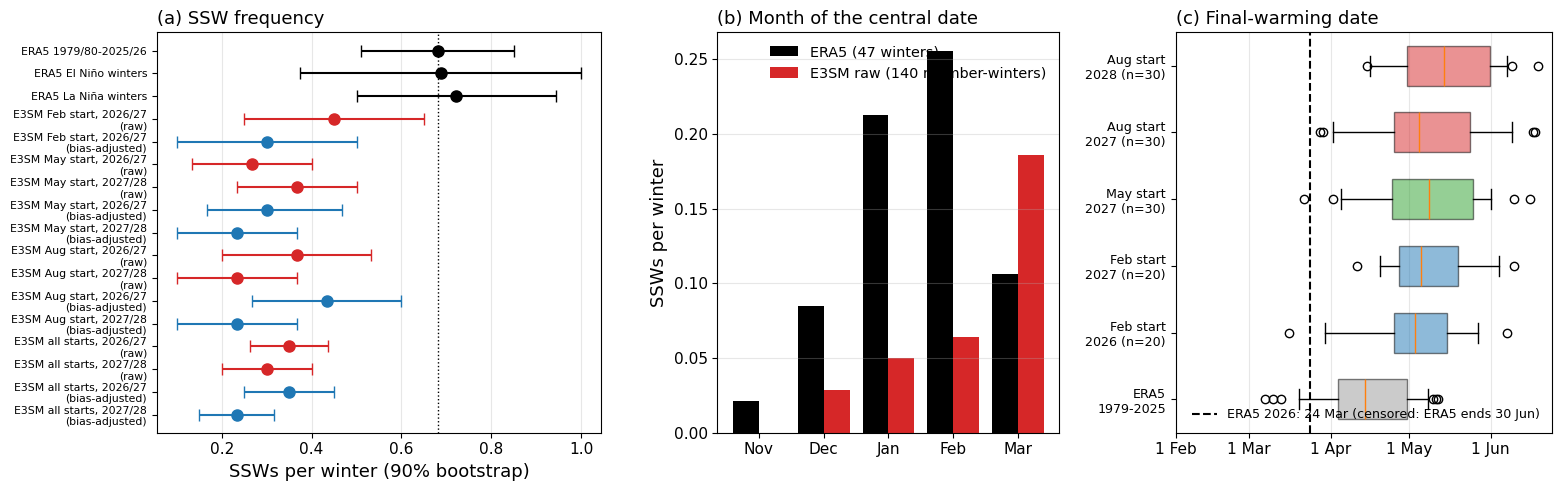

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9d_ssw_occurrence/data/final_warming_dates_2026.csv


In [8]:
# SSW frequency, central-date months and final-warming dates
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1.3, 1, 1.1], "wspace": 0.3})
ax = axes[0]
sel = freq[freq["set"].str.contains("ERA5") | freq["case"].astype(str).str.startswith("pooled")]
labels = [f"{s}\n({k})" if k != "ERA5" else s for s, k in zip(sel["set"], sel["wind"])]
colors = ["k" if k == "ERA5" else ("tab:red" if k == "raw" else "tab:blue") for k in sel["wind"]]
y = np.arange(len(sel))[::-1]
for yy, (_, r), c in zip(y, sel.iterrows(), colors):   # one call per point: errorbar takes one colour
    ax.errorbar(r["events per winter"], yy, xerr=[[r["events per winter"] - r["5%"]], [r["95%"] - r["events per winter"]]],
                fmt="o", color=c, ms=8, capsize=4, zorder=3)
ax.set_yticks(y, labels, fontsize=fontz * 0.6)
ax.axvline(float(freq.iloc[0]["events per winter"]), color="k", ls=":", lw=1)
ax.set_xlabel("SSWs per winter (90% bootstrap)")
ax.set_title("(a) SSW frequency", loc="left")
ax.grid(alpha=0.3, axis="x")

ax = axes[1]
order = [11, 12, 1, 2, 3]
x = np.arange(len(order))
obs_m = obs_events["central_date"].dt.month.value_counts().reindex(order, fill_value=0) / len(obs_winters)
mod = pd.concat([model_ssw[i] for i in INIT_MONTHS])
n_mw = sum(len(c) for (i, w, k), c in model_counts.items() if k == "raw")
mod_m = (mod["central_date"].dt.month.value_counts().reindex(order, fill_value=0) / max(n_mw, 1)) if len(mod) else 0 * obs_m
ax.bar(x - 0.2, obs_m.values, 0.4, color="k", label=f"ERA5 ({len(obs_winters)} winters)")
ax.bar(x + 0.2, np.asarray(mod_m), 0.4, color="tab:red", label=f"E3SM raw ({n_mw} member-winters)")
ax.set_xticks(x, [MONTH_NAMES[m] for m in order])
ax.set_ylabel("SSWs per winter")
ax.set_title("(b) Month of the central date", loc="left")
ax.legend(frameon=False)
ax.grid(alpha=0.3, axis="y")

ax = axes[2]


def doy_spring(d):
    return (pd.Timestamp(d) - pd.Timestamp(pd.Timestamp(d).year, 1, 1)).days + 1


# only complete records enter the boxes; censored and unresolved springs (record ends before 31 Jul,
# e.g. the May start's 2028) are tabulated but not plotted
obs_fw_status = {y: sc.final_warming(e_u60.values, e_u60["time"].values, y, recover_days=SSW["recover_days"])
                 for y in range(ERA5_FIRST_YEAR, obs_end.year + 1)}
obs_fw_doy = [doy_spring(d) for d, st in obs_fw_status.values() if st == "complete"]
data, labels, cols = [obs_fw_doy], [f"ERA5\n{ERA5_FIRST_YEAR}-{obs_end.year - 1}"], ["0.6"]
fw_rows = [{"source": "ERA5", "member": "ERA5", "spring": y, "final_warming": d, "status": st}
           for y, (d, st) in obs_fw_status.items()]
for init in INIT_MONTHS:
    u = m_u60[init]
    for spring in (YEAR, YEAR + 1, YEAR + 2):
        res = [sc.final_warming(u.sel(member=m).values, u["time"].values, spring, recover_days=SSW["recover_days"])
               for m in u["member"].values]
        if all(st == "no data" for _, st in res) or (spring == YEAR and init != 2):
            continue
        fw_rows += [{"source": f"E3SM init{init:02d}", "member": str(m), "spring": spring, "final_warming": d, "status": st}
                    for m, (d, st) in zip(u["member"].values, res)]
        ok = [d for d, st in res if st == "complete"]
        n_cens = sum(st in ("censored", "unresolved") for _, st in res)
        if n_cens:
            print(f"[final warming] {MONTH_NAMES[init]} start, spring {spring}: {n_cens} of {len(res)} members censored or "
                  f"unresolved (record ends {pd.Timestamp(u['time'].values[-1]):%d %b %Y}); not plotted")
        if len(ok) >= 3:
            data.append([doy_spring(d) for d in ok])
            labels.append(f"{MONTH_NAMES[init]} start\n{spring} (n={len(ok)})")
            cols.append(INIT_COLORS[init])
bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.6, whis=(5, 95))
for patch, c in zip(bp["boxes"], cols):
    patch.set_facecolor(c)
    patch.set_alpha(0.5)
d_obs, st_obs = obs_fw_status.get(YEAR, (pd.NaT, "no data"))
if pd.notna(d_obs):
    note = "" if st_obs == "complete" else f" ({st_obs}: ERA5 ends {obs_end:%d %b})"
    ax.axvline(doy_spring(d_obs), color="k", ls="--", lw=1.5, label=f"ERA5 {YEAR}: {d_obs:%d %b}{note}")
    ax.legend(frameon=False, loc="lower right", fontsize=fontz * 0.7)
ax.set_yticks(np.arange(1, len(labels) + 1), labels, fontsize=fontz * 0.7)
ticks = [pd.Timestamp(2001, m, 1) for m in (2, 3, 4, 5, 6)]
ax.set_xticks([doy_spring(t) for t in ticks], [f"1 {t:%b}" for t in ticks])
ax.set_title("(c) Final-warming date", loc="left")
ax.grid(alpha=0.3, axis="x")
save(fig, "ssw", "frequency", "final_warming", YEAR)
plt.show()

fw_table = pd.DataFrame(fw_rows)
fw_table.to_csv(DATA_DIR / f"final_warming_dates_{YEAR}.csv", index=False)
print(f"[WRITE] {DATA_DIR / f'final_warming_dates_{YEAR}.csv'}")